# Exploratory data analysis



In [24]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.special import logit, expit
from scipy.stats import norm
from sklearn.model_selection import GroupShuffleSplit
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from pandas.api.types import is_numeric_dtype
import matplotlib.pyplot as plt


In [4]:
train = pd.read_csv("train_augmented.csv",index_col=0)
train.columns

Index(['category_name', 'geography_name', 'wave_date', 'question_text',
       'qualifying_options', 'disqualifying_options', 'weight_3',
       'base_weight_3', 'percentage_3', 'timeframe_months', 'have_you_quest',
       'are_you_quest', 'multi_choice_quest', 'do_you_own_quest',
       'n_qualifying', 'n_disqualifying', 'qualifying_has_no',
       'qualifying_has_yes', 'continent', 'product_category', 'broad_category',
       'is_luxury', 'is_subscription', 'audience_breadth',
       'purchase_frequency', 'usage_frequency', 'cost_tier'],
      dtype='str')

# Overal distribution of target variable

<Axes: ylabel='Frequency'>

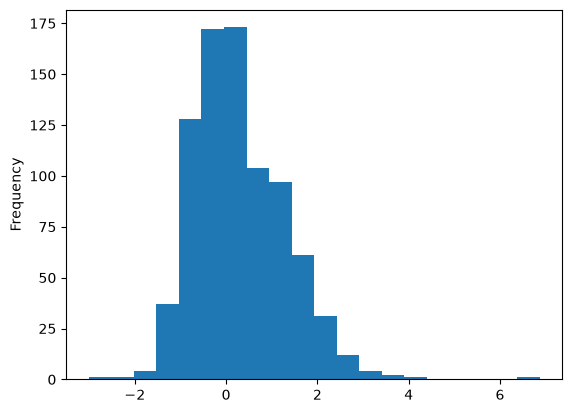

In [57]:
train["logit_incidence"] = logit( train_df_all["percentage_3"] )
train["logit_incidence"].plot.hist(bins=20)

# Feature correlations

<Axes: >

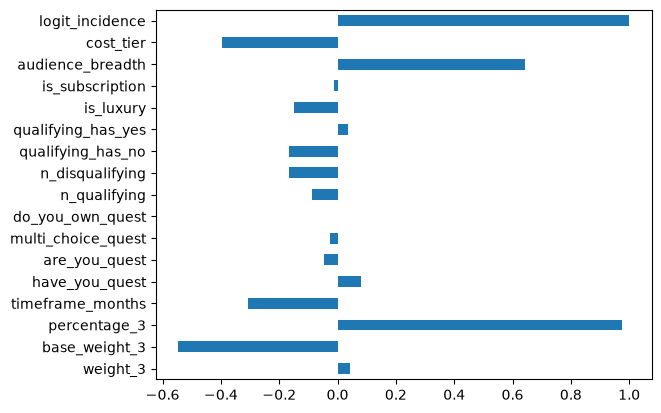

In [12]:
y = train["logit_incidence"]
corrs = {}
for col_name, col in train.items():
    if is_numeric_dtype(col):
        corrs[col_name] = np.corrcoef(y,col)[0,1]

pd.Series(corrs).plot.barh()

## Cross correlations between features

Do not use features that are highly correlated in a linear model

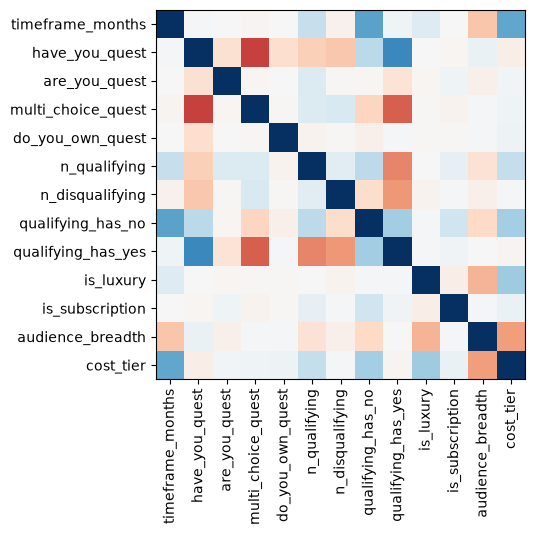

In [58]:
cols = ['category_name', 'geography_name', 'wave_date', 'question_text',
       'qualifying_options', 'disqualifying_options', 'timeframe_months', 'have_you_quest',
       'are_you_quest', 'multi_choice_quest', 'do_you_own_quest',
       'n_qualifying', 'n_disqualifying', 'qualifying_has_no',
       'qualifying_has_yes', 'continent', 'product_category', 'broad_category',
       'is_luxury', 'is_subscription', 'audience_breadth',
       'purchase_frequency', 'usage_frequency', 'cost_tier',
       ]

x_num = train[cols].select_dtypes(["number","bool"])

plt.imshow(x_num.corr(),cmap="RdBu",vmin=-1,vmax=1)
plt.xticks(np.arange(x_num.shape[1]),x_num.columns,rotation=90)
plt.yticks(np.arange(x_num.shape[1]),x_num.columns,rotation=0);

# Expected error of the incidence values

In [65]:
incidence_uncert = ((train.percentage_3*(1-train.percentage_3))**.5 / train.base_weight_3**.5)

margin_mult = norm.ppf(0.90)
logit_uncert = logit(incidence_uncert*margin_mult + train.percentage_3 ) - logit(-incidence_uncert*margin_mult + train.percentage_3 )
logit_uncert.describe()

count    828.000000
mean       0.152467
std        0.073108
min        0.041099
25%        0.113300
50%        0.130508
75%        0.170983
max        0.914334
dtype: float64

In [64]:
margin_mult

# Feature exploration

Investigate target distributions for some of the most promising features

<Axes: xlabel='audience_breadth', ylabel='percentage_3'>

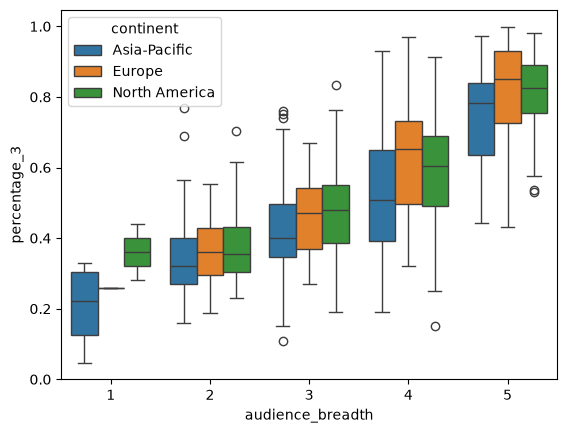

In [59]:
sns.boxplot(data=train_df_all, x="audience_breadth", y="percentage_3", hue="continent")

<Axes: xlabel='cost_tier', ylabel='percentage_3'>

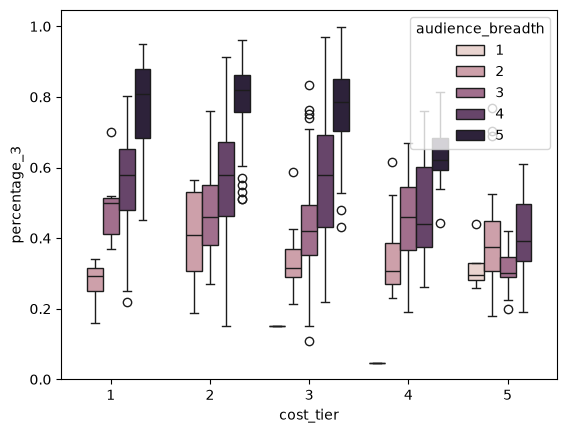

In [60]:
sns.boxplot(data=train_df_all, x="cost_tier", y="percentage_3", hue="audience_breadth")

<Axes: xlabel='timeframe_months', ylabel='percentage_3'>

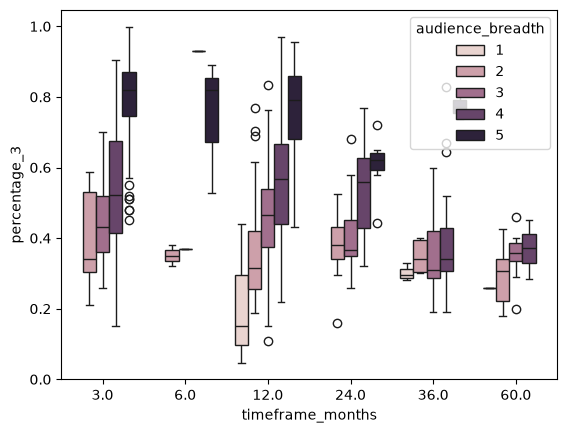

In [61]:
sns.boxplot(data=train_df_all, x="timeframe_months", y="percentage_3", hue="audience_breadth")